# 03 — Segmentation des régimes (Pump Sensor Data)

Objectifs :
1. Corriger trois points laissés ouverts par les phases 1 et 2 : stationnarité mesurée sur `NORMAL` seulement, épisode figé du 7 mai, `sensor_50`.
2. Identifier les régimes de fonctionnement sur les données nettoyées.
3. Vérifier leur stabilité en leave-one-failure-out (LOFO) : chaque pli apprend ses propres régimes sur sa zone `normal`.
4. Mesurer le lien entre régimes et pannes, et en tirer les règles de la phase 4.

Méthode (`src/regimes.py`) : médiane sur 10 min → imputation par la médiane → z-score robuste borné à ±10 → PCA (90 % de variance) → KMeans, k choisi par silhouette. Un point trop loin de son centre (au-delà du quantile 99,5 % des distances d'entraînement) est classé « hors régime ». Un changement de régime n'est confirmé qu'après 1 h (règle causale), et les 30 min suivantes forment la zone de transition.

Le dataset Pump n'a pas de variable de consigne : les régimes sont appris sur les capteurs eux-mêmes. C'est la limite principale de cette phase (voir constats).

Prérequis : `data/raw/sensor.csv`. Le nettoyage du notebook 02 est recalculé ici.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

from src.cleaning import clean_pump
from src.config import PRE_FAILURE_WINDOW, REGIME_RESAMPLE, TABLES
from src.data_loading import STATUS_COL, load_pump, pump_sensor_columns
from src.events import extract_failure_events, failure_cycles, lofo_folds, time_zones
from src.quality import classify_sensors, profile_sensors
from src.regimes import (HORS_REGIME, MANQUANT, RegimeModel, aggregate, confirm_regimes,
                         regime_table, transition_mask)
from src.viz import plot_regime_profile, plot_regime_timeline, plot_silhouette, save_fig

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)

## 1. Chargement et nettoyage

In [2]:
df = load_pump()
sensors = pump_sensor_columns(df)
events = extract_failure_events(df[STATUS_COL])

profile = profile_sensors(df, sensors)
classified = classify_sensors(profile)
dead = classified.index[classified["status"] == "mort"].tolist()
clean = clean_pump(df, sensors, dead_sensors=dead)
features = clean.features
print(f"{len(events)} pannes, {len(features)} capteurs utilisés comme variables")

7 pannes, 50 capteurs utilisés comme variables


## 2. Correctifs des phases 1 et 2

### 2.1 Stationnarité mesurée sur `NORMAL` uniquement

En phase 1, ADF/KPSS tournaient sur toute la série, arrêts compris. Les arrêts (jusqu'à 5 j 20 h) pouvaient créer à eux seuls des ruptures de niveau. On refait les tests en ne gardant que les instants `NORMAL`.

In [3]:
normal_only = profile_sensors(df, sensors, stationarity_mask=df[STATUS_COL] == "NORMAL")
compare = pd.DataFrame({
    "serie_complete": profile["stationarity"].value_counts(),
    "normal_seulement": normal_only["stationarity"].value_counts(),
}).fillna(0).astype(int)
display(compare)
changed = profile.index[profile["stationarity"] != normal_only["stationarity"]]
display(pd.DataFrame({"serie_complete": profile.loc[changed, "stationarity"],
                      "normal_seulement": normal_only.loc[changed, "stationarity"]}))

,serie_complete,normal_seulement
stationarity,,
contradictoire (ruptures / régimes probables),39,42
stationnaire,10,7
non stationnaire,2,2
non testable,1,1


,serie_complete,normal_seulement
sensor,,
sensor_05,stationnaire,contradictoire (ruptures / régimes probables)
sensor_09,stationnaire,contradictoire (ruptures / régimes probables)
sensor_43,stationnaire,contradictoire (ruptures / régimes probables)


### 2.2 Épisode figé du 7 mai : arrêt machine ou capteurs ?

`sensor_17`, `18`, `19` et `22` se figent le 7 mai vers 05h50, pendant ~4 jours, en statut `NORMAL`. Si la machine était arrêtée, toute la période devrait passer en zone `excluded`. On compare donc ces capteurs à `sensor_00` et `sensor_04`, qui chutent nettement pendant les remises en service (`RECOVERING`).

,pendant_RECOVERING,episode_7_11_mai
sensor_00,-44.599998,0.000000
sensor_04,-64.800003,-0.200000
sensor_10,-7.200000,-0.500000
sensor_14,0.100000,-137.399994
sensor_17,0.000000,-36.299999
sensor_19,-0.000000,-154.000000
sensor_20,-0.000000,-163.899994
sensor_22,0.000000,-9.700000
sensor_25,-0.000000,-13.300000
sensor_30,0.300000,-7.400000


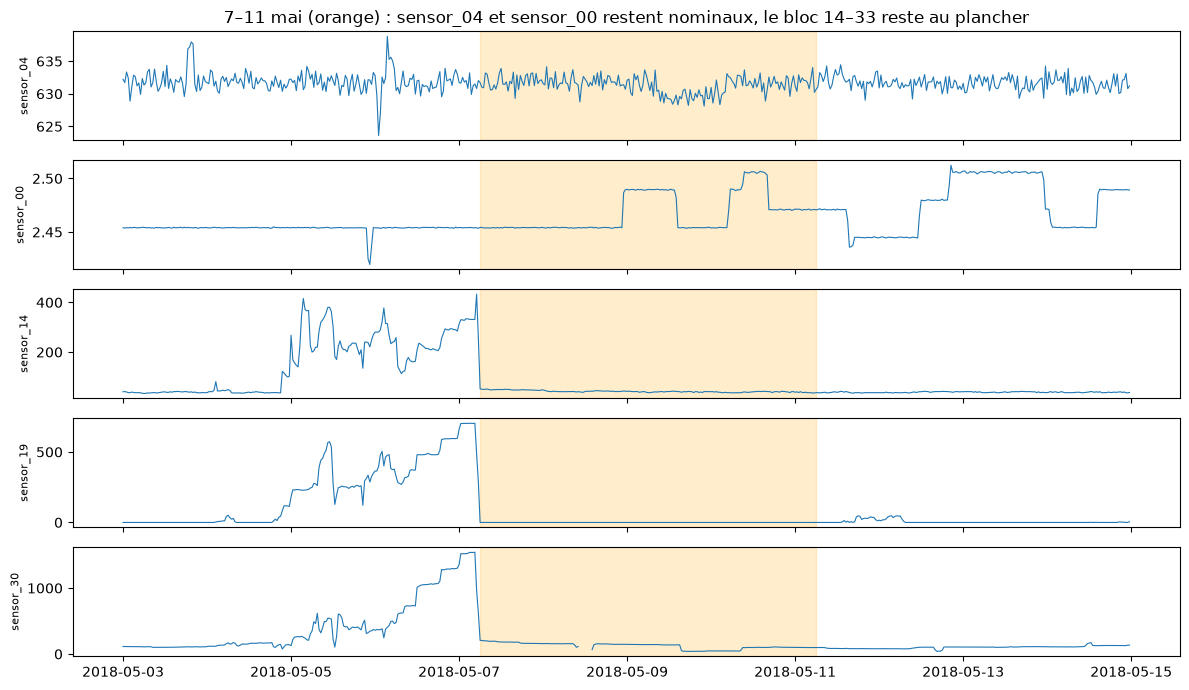

In [4]:
ref = df[STATUS_COL] == "NORMAL"
med = df.loc[ref, sensors].median()
iqr = (df.loc[ref, sensors].quantile(0.75) - df.loc[ref, sensors].quantile(0.25)).replace(0, 1)

def zmed(sel):
    return ((df.loc[sel, sensors].median() - med) / iqr).round(1)

episode = (df.index >= "2018-05-07 06:00") & (df.index < "2018-05-11 06:00")
z = pd.DataFrame({"pendant_RECOVERING": zmed(df[STATUS_COL] == "RECOVERING"),
                  "episode_7_11_mai": zmed(episode)})
display(z.loc[["sensor_00", "sensor_04", "sensor_10", "sensor_14", "sensor_17",
               "sensor_19", "sensor_20", "sensor_22", "sensor_25", "sensor_30"]])

cols = ["sensor_04", "sensor_00", "sensor_14", "sensor_19", "sensor_30"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 7), sharex=True)
w = df.loc["2018-05-03":"2018-05-14", cols].resample("30min").mean()
for ax, c in zip(axes, cols):
    ax.plot(w.index, w[c], lw=0.8)
    ax.set_ylabel(c, fontsize=8)
    ax.axvspan(pd.Timestamp("2018-05-07 05:50"), pd.Timestamp("2018-05-11 06:00"), color="orange", alpha=0.2)
axes[0].set_title("7–11 mai (orange) : sensor_04 et sensor_00 restent nominaux, le bloc 14–33 reste au plancher")
plt.tight_layout()
save_fig(fig, "03_episode_7_mai");

### 2.3 `sensor_50` : part de NaN par mois

In [5]:
display(df["sensor_50"].isna().resample("MS").mean().mul(100).round(1).to_frame("nan_pct"))
print("Dernière valeur valide :", df["sensor_50"].last_valid_index())

,nan_pct
timestamp,
2018-04-01,0.0
2018-05-01,0.0
2018-06-01,0.0
2018-07-01,72.5
2018-08-01,100.0


Dernière valeur valide : 2018-07-09 12:43:00


## 3. Données de la segmentation

Agrégation par médiane sur 10 min. Chaque pas reçoit la zone du protocole majoritaire et le numéro de cycle.

In [6]:
X = aggregate(clean.data, features, REGIME_RESAMPLE)
zones_min = time_zones(df[STATUS_COL], events, PRE_FAILURE_WINDOW)
zones = zones_min.resample(REGIME_RESAMPLE).agg(lambda s: s.mode().iat[0])
cycles = failure_cycles(df.index, events).resample(REGIME_RESAMPLE).max()
print(X.shape)
display(zones.value_counts().to_frame("n_pas_10min"))

(22032, 50)


,n_pas_10min
normal,18280
pre_failure,2015
excluded,1449
censored,288


## 4. Régimes appris sur toute la zone `normal` (vue exploratoire)

Ce modèle « global » sert uniquement à décrire les régimes. Il voit les 7 cycles : il ne doit **pas** servir à évaluer un détecteur. Les modèles utilisés en phase 4 sont ceux de la section 7, appris pli par pli.

k retenu : 2 ; composantes PCA : 10


,silhouette
2,0.597
3,0.555
4,0.365
5,0.371
6,0.392


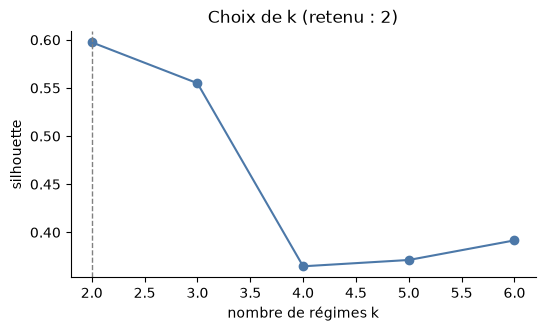

In [7]:
model = RegimeModel().fit(X[zones == "normal"])
print(f"k retenu : {model.k_} ; composantes PCA : {model.pca_.n_components_}")
display(pd.Series(model.silhouette_, name="silhouette").round(3).to_frame())
fig = plot_silhouette(model.silhouette_, model.k_)
save_fig(fig, "03_silhouette");

16 capteurs sur 50 diffèrent nettement (|z| > 2) entre régimes


,0,1
sensor_14,0.1,-10.0
sensor_16,0.1,-10.0
sensor_17,0.1,-3.4
sensor_18,0.1,-3.3
sensor_19,0.1,-10.0
sensor_20,0.2,-10.0
sensor_21,0.2,-10.0
sensor_22,0.0,-2.1
sensor_23,0.8,-4.3
sensor_24,0.0,-10.0


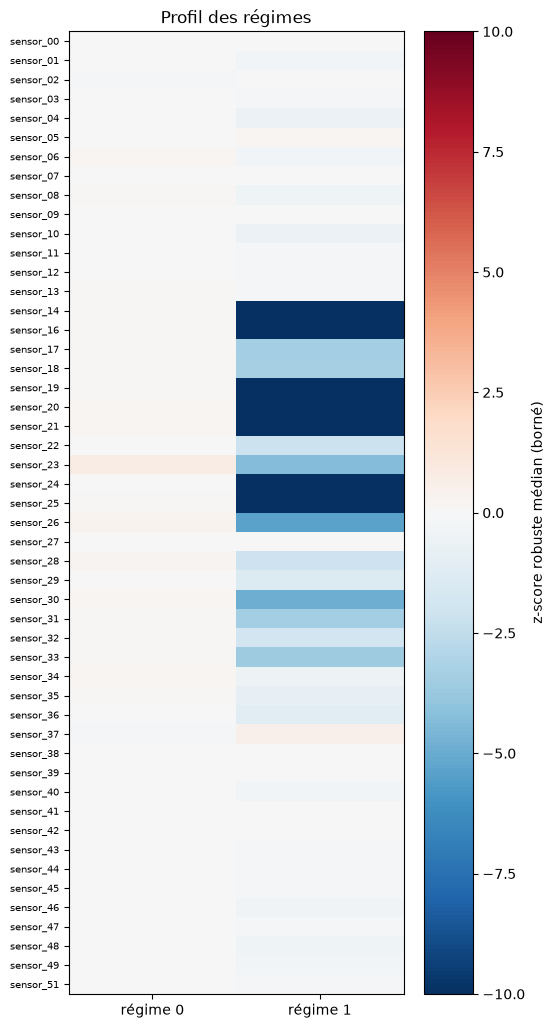

In [8]:
raw_labels = model.predict(X)
labels = confirm_regimes(raw_labels)
prof = model.profile(X, labels)
marked = prof.loc[(prof.abs() > 2).any(axis=1)]
print(f"{len(marked)} capteurs sur {len(prof)} diffèrent nettement (|z| > 2) entre régimes")
display(marked.round(1))
fig = plot_regime_profile(prof)
save_fig(fig, "03_profil_regimes");

## 5. Chronologie des régimes

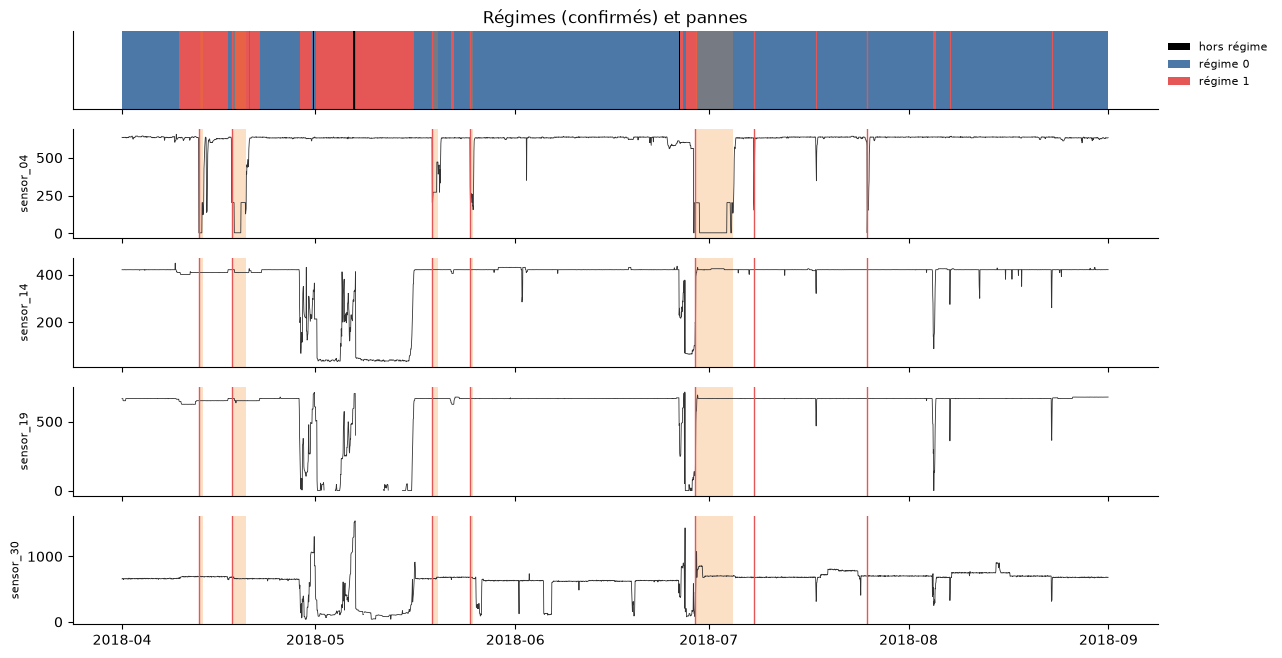

In [9]:
signals = X[["sensor_04", "sensor_14", "sensor_19", "sensor_30"]].resample("1h").median()
fig = plot_regime_timeline(labels, events, signals)
save_fig(fig, "03_chronologie_regimes");

In [10]:
runs = labels.ne(labels.shift()).cumsum()
episodes = labels.groupby(runs).agg(regime="first", debut=lambda s: s.index[0], fin=lambda s: s.index[-1])
episodes["duree"] = episodes["fin"] - episodes["debut"] + pd.Timedelta(REGIME_RESAMPLE)
long_eps = episodes[(episodes["regime"] >= 1) & (episodes["duree"] >= pd.Timedelta("6h"))]
display(long_eps.reset_index(drop=True))

,regime,debut,fin,duree
0,1,2018-04-09 20:50:00,2018-04-13 16:20:00,3 days 19:40:00
1,1,2018-04-13 17:20:00,2018-04-17 11:10:00,3 days 18:00:00
2,1,2018-04-18 12:10:00,2018-04-20 17:30:00,2 days 05:30:00
3,1,2018-04-21 01:40:00,2018-04-22 08:40:00,1 days 07:10:00
4,1,2018-04-28 13:20:00,2018-04-29 13:50:00,1 days 00:40:00
5,1,2018-04-29 14:40:00,2018-04-30 09:30:00,0 days 19:00:00
6,1,2018-05-01 01:30:00,2018-05-05 00:00:00,3 days 22:40:00
7,1,2018-05-05 03:30:00,2018-05-06 18:50:00,1 days 15:30:00
8,1,2018-05-07 06:30:00,2018-05-16 08:00:00,9 days 01:40:00
9,1,2018-05-22 01:30:00,2018-05-22 11:10:00,0 days 09:50:00


## 6. Lien entre régimes et pannes

In [11]:
table = regime_table(labels, zones, [e.failure_time for e in events])
table.to_csv(TABLES / "regimes_resume.csv")
display(table.round(2))

rows = []
ones = episodes[episodes["regime"] == 1]
for e in events:
    start = e.failure_time - pd.Timedelta(PRE_FAILURE_WINDOW)
    w = labels[(labels.index >= start) & (labels.index < e.failure_time)]
    overlap = ones[(ones["fin"] >= start) & (ones["debut"] < e.failure_time)]
    debut = overlap["debut"].min() if len(overlap) else pd.NaT
    rows.append({
        "panne": e.event_id,
        "t_f": e.failure_time,
        "part_regime_1_48h_pct": round(100 * (w == 1).mean(), 1),
        "debut_episode_regime_1": debut,
        "avance_h": round((e.failure_time - debut) / pd.Timedelta("1h"), 1) if pd.notna(debut) else None,
        "regime_1h_avant": int(labels[labels.index < e.failure_time - pd.Timedelta("1h")].iloc[-1]),
    })
per_failure = pd.DataFrame(rows).set_index("panne")
per_failure.to_csv(TABLES / "regimes_par_panne.csv")
display(per_failure)

,part_temps_pct,n_episodes,duree_episode_med,jours_avant_panne_med,part_pre_panne_pct
regime,,,,,
-1,0.490196,18,0 days 00:20:00,12.283333,0.0
0,78.907952,24,0 days 15:45:00,12.444444,7.987778
1,20.601852,27,0 days 03:20:00,9.922222,17.623049


,t_f,part_regime_1_48h_pct,debut_episode_regime_1,avance_h,regime_1h_avant
panne,,,,,
1,2018-04-12 21:55:00,100.0,2018-04-09 20:50:00,73.1,1
2,2018-04-18 00:30:00,72.6,2018-04-13 17:20:00,103.2,0
3,2018-05-19 03:18:00,0.0,NaT,NaN,0
4,2018-05-25 00:30:00,0.0,NaT,NaN,0
5,2018-06-28 22:00:00,82.6,2018-06-26 14:30:00,55.5,1
6,2018-07-08 00:11:00,0.0,NaT,NaN,0
7,2018-07-25 14:00:00,0.0,NaT,NaN,0


### 6.1 Variante k = 3

Le régime 1 mélange deux niveaux très différents : en avril, le bloc ne baisse que de 2 à 3 %, mais l'écart interquartile de ces capteurs est minuscule (2 à 5 unités), donc le z-score sature quand même à −10. En mai et fin juin, il s'effondre de 80 à 100 %. La silhouette de k = 3 (0,555) est proche de celle de k = 2 : on regarde ce que la troisième classe sépare.

In [12]:
model3 = RegimeModel(n_regimes=3).fit(X[zones == "normal"])
labels3 = confirm_regimes(model3.predict(X))
prof3 = model3.profile(X, labels3)
display(prof3.loc[(prof3.abs() > 2).any(axis=1)].round(1))
display(pd.crosstab(labels3.index.to_period("M"), labels3).rename_axis(index="mois", columns="regime"))

rows = []
for e in events:
    w = labels3[(labels3.index >= e.failure_time - pd.Timedelta(PRE_FAILURE_WINDOW)) & (labels3.index < e.failure_time)]
    rows.append({"panne": e.event_id, **(100 * w.value_counts(normalize=True)).round(1).add_prefix("regime_").to_dict()})
per_failure3 = pd.DataFrame(rows).set_index("panne").fillna(0)
per_failure3.to_csv(TABLES / "regimes_k3_par_panne.csv")
display(per_failure3)

,0,1,2
sensor_14,0.1,-10.0,-10.0
sensor_16,0.1,-10.0,-8.2
sensor_17,0.1,-10.0,-3.1
sensor_18,0.1,-10.0,-3.0
sensor_19,0.1,-10.0,-10.0
sensor_20,0.2,-10.0,-10.0
sensor_21,0.2,-10.0,-8.5
sensor_22,0.0,-10.0,-2.1
sensor_23,0.8,-6.3,-0.2
sensor_24,0.0,-10.0,-0.5


regime,-1,0,1,2
mois,,,,
2018-04,39,2219,190,1872
2018-05,63,2133,1967,301
2018-06,29,3944,269,78
2018-07,118,4336,0,10
2018-08,0,4346,67,51


,regime_2,regime_0,regime_1,regime_-1
panne,,,,
1,100.0,0.0,0.0,0.0
2,72.6,27.4,0.0,0.0
3,0.0,100.0,0.0,0.0
4,0.0,100.0,0.0,0.0
5,11.5,10.1,77.1,1.4
6,0.0,100.0,0.0,0.0
7,0.0,100.0,0.0,0.0


## 7. Stabilité en LOFO

Pour chaque panne k, un modèle est appris sur la zone `normal` des autres cycles, avec la purge de 24 h du protocole. On mesure :
- `k` choisi dans le pli ;
- `ari` : accord (indice de Rand ajusté) avec le modèle global, sur tous les pas valides ;
- `hors_regime_normal_pct` et `hors_regime_pre_pct` : part de pas « hors régime » dans le cycle de test, en zone `normal` et en fenêtre pré-panne ;
- `regime1_normal_pct` et `regime1_pre_pct` : même chose pour le régime 1.

Contrôle chronologique (entraînement sur les cycles < k) présenté à côté.

In [13]:
def run_folds(chronological):
    rows = []
    for k, train, test in lofo_folds(zones, cycles, events, chronological=chronological):
        m = RegimeModel().fit(X[train])
        lab = confirm_regimes(m.predict(X))
        both = (lab >= 0) & (labels >= 0)
        zt, lt = zones[test], lab[test]
        rows.append({
            "pli": k,
            "k": m.k_,
            "n_train": int(train.sum()),
            "ari": adjusted_rand_score(labels[both], lab[both]),
            "hors_regime_normal_pct": 100 * (lt[zt == "normal"] == HORS_REGIME).mean(),
            "hors_regime_pre_pct": 100 * (lt[zt == "pre_failure"] == HORS_REGIME).mean(),
            "regime1_normal_pct": 100 * (lt[zt == "normal"] == 1).mean(),
            "regime1_pre_pct": 100 * (lt[zt == "pre_failure"] == 1).mean(),
        })
    return pd.DataFrame(rows).set_index("pli")

lofo = run_folds(chronological=False)
chrono = run_folds(chronological=True)
lofo.to_csv(TABLES / "regimes_lofo.csv")
chrono.to_csv(TABLES / "regimes_chrono.csv")
print("LOFO"); display(lofo.round(2))
print("Contrôle chronologique"); display(chrono.round(2))

LOFO


,k,n_train,ari,hors_regime_normal_pct,hors_regime_pre_pct,regime1_normal_pct,regime1_pre_pct
pli,,,,,,,
1,2,16708,0.99,0.00,0.0,10.57,100.00
2,2,17783,0.99,8.22,0.0,91.78,72.57
3,2,14254,0.94,4.25,0.0,70.56,0.00
4,2,17709,1.00,0.00,0.0,13.79,0.00
5,2,13460,0.65,0.00,0.0,1.45,82.29
6,2,17954,1.00,0.00,0.0,0.00,0.00
7,2,15898,1.00,0.00,0.0,0.58,0.00


Contrôle chronologique


,k,n_train,ari,hors_regime_normal_pct,hors_regime_pre_pct,regime1_normal_pct,regime1_pre_pct
pli,,,,,,,
2,3,1428,0.91,26.35,2.78,0.00,0.00
3,2,1781,0.26,27.18,0.00,34.34,32.29
4,2,5663,0.17,1.87,0.35,22.66,15.97
5,3,6091,0.21,0.02,52.43,31.99,0.00
6,2,10767,0.61,4.95,0.00,0.00,0.00
7,2,10949,0.62,0.00,0.00,0.36,0.00


## 8. Transitions

In [14]:
trans = transition_mask(labels)
n_changes = int((labels.where(labels >= 0).ffill().diff().fillna(0) != 0).sum())
print(f"{n_changes} changements de régime confirmés")
print(f"Zone de transition : {100 * trans.mean():.2f} % du temps")
print(f"Rafales filtrées par la confirmation (1 h) : {int((raw_labels != labels).sum())} pas sur {len(labels)}")

32 changements de régime confirmés
Zone de transition : 0.44 % du temps
Rafales filtrées par la confirmation (1 h) : 193 pas sur 22032


## 9. Constats

**Correctifs des phases 1 et 2**

- **Stationnarité** : sur `NORMAL` seulement, 42 capteurs sont « contradictoires » au lieu de 39 (`sensor_05`, `09`, `43` basculent). Les ruptures ne viennent donc pas des arrêts : elles existent en fonctionnement normal, ce que confirme la segmentation ci-dessous. Le constat de la phase 1 tient.
- **Épisode du 7 mai** : ce n'est pas un arrêt machine. `sensor_00` et `sensor_04`, qui chutent fortement en `RECOVERING` (z ≈ −45 et −65), restent nominaux (z ≈ 0). C'est le bloc `sensor_14` à `sensor_33` qui est au plancher (jusqu'à z ≈ −160) : il l'est déjà depuis fin avril, et les capteurs figés en font partie. La période reste en zone `normal` et le masquage des valeurs figées est conservé. L'épisode appartient au régime 1.
- **`sensor_50`** : il cesse d'émettre le 2018-07-09 à 12h43 (72 % de NaN en juillet, 100 % en août). Son exclusion est structurelle : il manquerait entièrement dans les cycles de test 6 et 7. Décider cette exclusion sur tout le jeu n'est donc pas une fuite.

**Régimes**

- **Deux régimes nets** (silhouette 0,60 pour k = 2, puis décroissante). La PCA garde 10 composantes.
  - **Régime 0, nominal** : 79 % du temps.
  - **Régime 1, « bloc 14–33 effondré »** : 21 % du temps. 16 capteurs sur 50 s'en écartent nettement, tous dans le bloc `sensor_14` à `sensor_33` (z jusqu'à −10, valeur de la borne). `sensor_00` à `sensor_13` et `sensor_34` à `sensor_51` ne changent pas.
- **Chronologie** : le régime 1 occupe presque toute la période du 9 avril au 16 mai (épisode le plus long : 9 jours, du 7 au 16 mai). Ailleurs, il n'apparaît que du 26 au 29 juin (juste avant la panne 5) et quelques heures les 4 et 5 août.
- **Lien avec les pannes** : le régime 1 couvre 73 à 100 % de la fenêtre pré-panne des pannes 1, 2 et 5. L'épisode en cours commence 73 h, 103 h et 55 h avant la panne. Pour la panne 2, il se termine environ 13 h avant `t_f` : c'est le changement brusque de niveau vu vers −14 h sur la carte de chaleur de la phase 1. Le régime 1 est absent avant les pannes 3, 4, 6 et 7. Il est deux fois plus fréquent en pré-panne qu'en zone normale (17,6 % contre 8,0 % des pas). Mais il occupe aussi 71 à 92 % de la zone normale des cycles 2 et 3, pendant des jours, sans panne. **Ce n'est donc ni un simple régime de fonctionnement, ni un précurseur fiable** : c'est un mode dégradé (une partie de l'installation à l'arrêt ou une perte d'acquisition sur ce bloc) que trois pannes traversent.
- **Le régime 1 regroupe deux états différents.** En avril, autour des pannes 1 et 2, le bloc ne baisse que de 2 à 3 % (`sensor_14` : 408 contre 420). Mais l'écart interquartile de ces capteurs est minuscule (2 à 5 unités), donc le z-score sature à −10. En mai et fin juin, le bloc s'effondre de 80 à 100 % (`sensor_14` ≈ 40 à 70, `sensor_19` ≈ 0). **Avec k = 3**, ces deux états se séparent proprement : le régime 2 est le « léger décalage » (100 % et 73 % des fenêtres des pannes 1 et 2), le régime 1 est l'« effondrement » (77 % de la fenêtre de la panne 5, et presque tout le mois de mai). La silhouette (0,555 contre 0,597) ne suffit pas à trancher entre les deux.
- **Stabilité en LOFO** : les 7 plis retrouvent k = 2. L'accord avec le modèle global est très bon (ARI de 0,94 à 1,00), sauf pour le pli 5 (0,65). La segmentation ne dépend donc pas du cycle retiré.
- **Contrôle chronologique** : la segmentation est instable tant qu'il y a peu d'historique. L'ARI vaut 0,17 à 0,26 pour les plis 3 à 5, avec seulement 1 800 à 6 100 pas d'entraînement, puis remonte à environ 0,6. Le pli 2 retrouve un ARI de 0,91, mais il n'a que 1 400 pas d'entraînement. En usage réel, les régimes ne seraient pas fiables avant environ 2 mois d'historique.
- **« Hors régime »** : 0 % des pas pré-panne en LOFO. L'enveloppe de 99,5 % ne détecte rien seule. Elle reste utile pour repérer les états jamais vus (8 % de la zone normale du cycle 2).
- **Transitions** : 32 changements confirmés. La zone de transition de 30 min ne couvre que 0,44 % du temps : la masquer ne coûte presque rien. La confirmation d'1 h filtre 193 pas de rafales.

**Conséquences pour la phase 4 (à valider ensemble)**

1. **Pas de seuil par régime par défaut.** k = 2 et k = 3 passent tous deux en ablation. Normaliser par régime rendrait « normal » le régime 1 (ou les régimes 1 et 2 avec k = 3), donc effacerait le signal des pannes 1, 2 et 5. À l'inverse, ne pas le faire génère des fausses alertes sur les longues périodes en régime 1 des cycles 2 et 3. Les deux variantes passent en **ablation** (protocole, section 5), et c'est l'ablation qui décide.
2. Les régimes sont appris **dans chaque pli** avec `RegimeModel().fit(X[train])`, jamais avec le modèle global de la section 4.
3. Le **régime est donné comme contexte** aux détecteurs (une variable de plus, ou un modèle par régime en variante). Le masquage des transitions s'applique dans tous les cas.
4. Pour la phase 5, l'**entrée en régime 1** est un précurseur candidat, à évaluer comme un détecteur à part entière (rappel attendu au mieux 3/7).
5. La saturation du z-score sur des capteurs très stables gonfle des écarts de 2 à 3 %. En phase 4, il faut **borner l'échelle par le bas** (par exemple max(IQR, 1 % de la médiane)) ou standardiser par l'écart-type.
6. Avec un seul bloc qui bascule, une **PCA (T², SPE) séparée sur `sensor_14`–`sensor_33`** et sur le reste vaut la peine d'être testée : une anomalie du reste de la machine ne serait plus noyée par le bloc.